# 미관측 링크 계층 분리 평가 — 이웃 속도 피처는 어디서 통하고 어디서 깨지는가

**한 줄 요약**: 지금까지 하나의 R²로 보고하던 "미관측 링크 성능"을 **이웃 관측 유무로 쪼개서** 다시 측정하고, 그 결과 드러난 문제와 해결책을 비교합니다.

---

## 왜 이 노트북이 필요한가

`12_derived_features_lightgbm.ipynb`에서 **인접 실측 이웃 속도**가 압도적으로 효과적이라는 게 확인됐습니다(R² 0.625 → 0.744). 하지만 그 숫자는 테스트 링크 전체를 한 덩어리로 평균낸 값입니다.

문제는 서울 도로가 예측 난이도 면에서 **성격이 전혀 다른 세 집단**으로 나뉜다는 것입니다.

| 계층 | 정의 | 배포 시 쓸 수 있는 정보 |
| --- | --- | --- |
| **A** | 5분 데이터에 속도가 관측되는 링크 | 자기 자신의 과거 속도 이력 (Model A) |
| **B** | 미관측 + 1홉 이내에 관측 링크가 있음 | 이웃의 실측 속도 |
| **C** | 미관측 + 1홉 이내에 관측 링크가 **없음** | 정적 피처(도로·시간·지형·날씨·교통량)뿐 |

이웃 속도 피처는 정의상 **B에서만 값이 존재**합니다. C에서는 결측입니다.
그런데 평가는 A·B·C를 섞어서 하니, **C에서 무슨 일이 일어나는지 아무도 모르는 상태**였습니다.

C는 서울 전체 링크의 7.2%, 연장 402km에 해당합니다. 에너지 최적 경로가 이 구간을 지나가면 그 구간의 속도 예측은 곧 에너지 추정의 신뢰도가 됩니다. 무시할 수 있는 크기가 아닙니다.

## 이 노트북이 답하는 질문

1. C 계층의 실제 예측 성능은 얼마인가? (아무도 측정한 적 없음)
2. 이웃 속도 피처를 넣으면 C는 어떻게 되는가?
3. View-T 추정교통량 같은 정적 피처의 기여도가 "전체 평균에 묻혀서" 작아 보였던 것인가?
4. 문제가 있다면 어떻게 고치는가?

## 방법 요약

- 관측 링크 44,960개를 **강제로 숨겨서** 미관측 상황을 재현합니다(GroupKFold).
- 분할을 **두 가지**로 합니다. 이웃 보유율이 분할 방식에 따라 극단적으로 달라지기 때문입니다.
  - **링크 랜덤분할**: 12번 노트북과 같은 방식. 링크를 무작위로 숨김 → 이웃 보유율이 높게 나옴
  - **공간 블록분할(2km)**: 지리적으로 인접한 링크를 통째로 숨김 → 실제 미관측 지역과 비슷한 상황
- 각 분할에서 테스트 링크를 **B(이웃 있음)/C(이웃 없음)** 로 나눠 R²·MAE를 따로 냅니다.
- 피처를 누적해가며(S1→S4) 계층별 기여도를 봅니다.

> **참고**: 버스전용차로 겹침비율(12번)과 스쿨존/사고다발/과속방지턱(팀원 실험)은 이 저장소 `data/raw`에 원본이 없어 이번 실험에서는 제외했습니다. 두 피처군 모두 링크 단위 정적 피처라 아래 S2와 같은 계층에 속하며, 같은 방식으로 A/B/C 분리 평가를 붙일 수 있습니다.

In [1]:
import platform
import time
from collections import defaultdict
from pathlib import Path

import geopandas as gpd
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
INTERIM_DIR = PROJECT_ROOT / "data" / "interim"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "docs" / "figures" / "model"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CACHE_PATH = INTERIM_DIR / "nb13_feature_cache.parquet"
SPEED_PATH = PROCESSED_DIR / "seoul_link_speed_dem_weather_merged.csv"
ATTR_PATH = PROCESSED_DIR / "seoul_link_attr.csv"
LINK_SHP = INTERIM_DIR / "seoul_link.shp"
VOLUME_XLSX = RAW_DIR / "traffic" / "TrafficVolume(LINK) (1).xlsx"
LEV6_SHP = RAW_DIR / "traffic" / "seoul_lev6_2024" / "seoul_link_lev6_2024.shp"

# macOS/Windows 모두에서 한글이 깨지지 않도록
plt.rcParams["font.family"] = "AppleGothic" if platform.system() == "Darwin" else "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
N_FOLDS = 3
SAMPLE_FRAC = 1.0          # 빠르게 돌려볼 때 0.15 정도로 낮추면 5분 안에 끝납니다(결론은 동일)
BLOCK_SIZE_M = 2000        # 공간 블록분할 격자 한 변 길이

COLOR_B = "#2a78d6"
COLOR_C = "#eb6834"
COLOR_ALL = "#8a8f98"


## 1. 서울 도로를 A / B / C로 나눈다

먼저 **실제 서울이 지금 어떤 상태인지**를 셉니다. 평가와는 별개로, 배포 시점에 우리가 마주하는 현실입니다.

- 관측 여부: `seoul_link_speed_5min_hourly.csv`에 속도가 있는가
- 이웃: 표준노드링크 위상(`F_NODE`/`T_NODE`)으로 노드를 공유하는 1홉 인접 링크

In [2]:
attr = pd.read_csv(ATTR_PATH, dtype=str)
attr["LENGTH_m"] = pd.to_numeric(attr["LENGTH"], errors="coerce")

speed_links = pd.read_csv(
    PROCESSED_DIR / "seoul_link_speed_5min_hourly.csv",
    dtype={"LINK_ID": str}, usecols=["LINK_ID"], encoding="utf-8-sig",
)
observed = set(speed_links["LINK_ID"].unique())
all_links = set(attr["LINK_ID"])

# 1홉 인접 그래프 (노드 공유)
node_to_links = defaultdict(set)
for lid, fn, tn in zip(attr["LINK_ID"], attr["F_NODE"], attr["T_NODE"]):
    node_to_links[fn].add(lid)
    node_to_links[tn].add(lid)

neighbors = defaultdict(set)
for group in node_to_links.values():
    for lid in group:
        neighbors[lid] |= (group - {lid})

unobserved = all_links - observed
tier_b = {l for l in unobserved if neighbors[l] & observed}
tier_c = unobserved - tier_b

tiers = pd.Series("A 관측", index=sorted(all_links))
tiers[sorted(tier_b)] = "B 미관측·이웃있음"
tiers[sorted(tier_c)] = "C 미관측·이웃없음"
attr["tier"] = attr["LINK_ID"].map(tiers)

summary = attr.groupby("tier").agg(
    링크수=("LINK_ID", "size"),
    연장_km=("LENGTH_m", lambda s: s.sum() / 1000),
)
summary["링크_비중"] = (summary["링크수"] / len(attr) * 100).round(1)
summary["연장_비중"] = (summary["연장_km"] / summary["연장_km"].sum() * 100).round(1)
summary["연장_km"] = summary["연장_km"].round(0)
print(summary.to_string())

              링크수   연장_km  링크_비중  연장_비중
tier                                   
A 관측        44960  4858.0   70.7   80.3
B 미관측·이웃있음  14006   787.0   22.0   13.0
C 미관측·이웃없음   4582   402.0    7.2    6.6


In [3]:
print("=== 미관측 링크(B+C)의 도로등급 구성 ===")
rank_name = {"101": "고속국도", "102": "도시고속국도", "103": "일반국도", "104": "특별광역시도",
             "105": "국가지원지방도", "106": "지방도", "107": "시군도", "108": "고속도로 연결램프"}
rank_tbl = (attr.assign(등급=attr["ROAD_RANK"].map(rank_name).fillna(attr["ROAD_RANK"]))
                .pivot_table(index="등급", columns="tier", values="LINK_ID", aggfunc="size", fill_value=0))
rank_tbl["관측률"] = (rank_tbl.get("A 관측", 0) / rank_tbl.sum(axis=1) * 100).round(1)
print(rank_tbl.sort_values("관측률").to_string())

=== 미관측 링크(B+C)의 도로등급 구성 ===
tier      A 관측  B 미관측·이웃있음  C 미관측·이웃없음    관측률
등급                                           
시군도        886         425         238   57.2
특별광역시도   39058       13513        4342   68.6
고속국도       342           9           1   97.2
도시고속국도    1365          23           0   98.3
일반국도      3021          35           1   98.8
국가지원지방도    120           1           0   99.2
지방도        168           0           0  100.0


### 여기서 이미 하나가 정리됩니다

미관측 링크는 사실상 전부 **특별광역시도(시내 일반도로)** 입니다. 고속국도·도시고속국도·일반국도는 이미 97% 이상 관측되고 있습니다.

→ 서울 열린데이터광장의 **도시고속도로 5분단위 링크 속도(OA-22351)** 를 추가로 받아도 얻을 게 거의 없습니다. 이미 덮여 있는 구간이기 때문입니다. 추가 데이터를 찾는다면 **시내 일반도로의 지체를 설명하는 것**이어야 합니다.

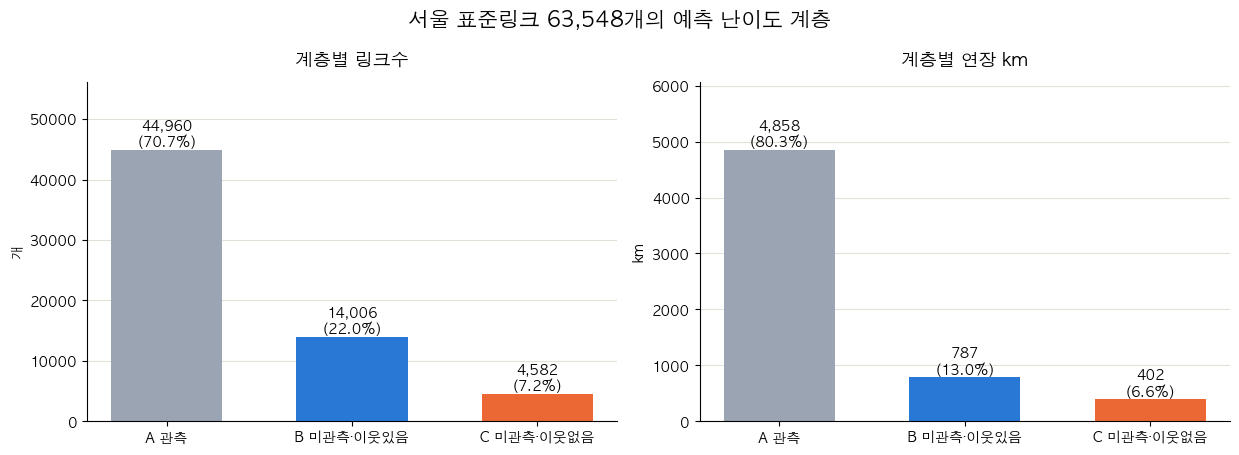

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
order = ["A 관측", "B 미관측·이웃있음", "C 미관측·이웃없음"]
colors = ["#9aa4b2", COLOR_B, COLOR_C]

for ax, col, unit in zip(axes, ["링크수", "연장_km"], ["개", "km"]):
    vals = summary.loc[order, col]
    bars = ax.bar(order, vals, color=colors, width=0.6)
    ax.set_title(f"계층별 {col.replace('_', ' ')}", fontsize=13, fontweight="bold", pad=12)
    ax.set_ylabel(unit)
    for bar, v, pct in zip(bars, vals, summary.loc[order, "링크_비중" if col == "링크수" else "연장_비중"]):
        ax.text(bar.get_x() + bar.get_width() / 2, v, f"{v:,.0f}\n({pct}%)",
                ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_ylim(0, vals.max() * 1.25)
    ax.tick_params(axis="x", labelsize=10)

fig.suptitle("서울 표준링크 63,548개의 예측 난이도 계층", fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_tier_abc_size.png", dpi=220, bbox_inches="tight")
plt.show()

## 2. 데이터 로드

5분 집계 결합 데이터(`seoul_link_speed_dem_weather_merged.csv`, 15.1M행 / 5.2GB)에서 필요한 컬럼만 뽑고,
View-T 추정교통량과 링크 중심좌표(공간 블록분할용)를 붙여 parquet으로 캐싱합니다. 캐시가 있으면 바로 읽습니다.

In [5]:
NUM_COLS = ["LANES", "MAX_SPD", "LENGTH", "시간코드", "elev_mean_m", "elev_delta_m",
            "slope_pct", "abs_slope_pct", "precip_mm"]
CAT_COLS = ["ROAD_RANK", "ROAD_TYPE", "ROAD_USE", "MULTI_LINK", "CONNECT",
            "REST_VEH", "REST_W", "REST_H", "C-ITS"]
TARGET = "평균속도"


def build_cache() -> pd.DataFrame:
    dtype = {c: str for c in CAT_COLS} | {"LINK_ID": str, "기준일": str}
    chunks = []
    reader = pd.read_csv(SPEED_PATH, usecols=["LINK_ID", "기준일", TARGET] + NUM_COLS + CAT_COLS,
                         dtype=dtype, encoding="utf-8-sig", chunksize=2_000_000)
    for chunk in reader:
        for c in NUM_COLS + [TARGET]:
            chunk[c] = pd.to_numeric(chunk[c], errors="coerce").astype("float32")
        chunks.append(chunk.dropna(subset=[TARGET]))
    out = pd.concat(chunks, ignore_index=True)

    d = pd.to_datetime(out["기준일"], format="%Y%m%d")
    out["dow"] = d.dt.weekday.astype("int8")
    out["is_weekend"] = (out["dow"] >= 5).astype("int8")
    h = out["시간코드"].astype("float32")
    out["hour_sin"] = np.sin(2 * np.pi * h / 24).astype("float32")
    out["hour_cos"] = np.cos(2 * np.pi * h / 24).astype("float32")

    # View-T 추정교통량: ITS LINK ID가 콤마로 묶인 셀이 있어 펼쳐서 매칭 (12번 노트북과 동일 로직)
    tv_names = ["LEVEL55_LINK_ID", "ITS_LINK_ID", "road_rank_tv", "road_name_tv",
                "region_tv", "length_km_tv", "lanes_tv", "aadt"] + [f"vol_h{k}" for k in range(1, 25)]
    tv = pd.read_excel(VOLUME_XLSX, sheet_name="Sheet0", header=6, skiprows=[7])
    tv.columns = tv_names
    tv_exp = tv.assign(ids=tv["ITS_LINK_ID"].astype(str).str.split(",")).explode("ids")
    tv_exp["LINK_ID"] = tv_exp["ids"].str.strip()
    tv_exp = tv_exp[tv_exp["LINK_ID"] != "0"]

    aadt = tv_exp.groupby("LINK_ID", as_index=False)["aadt"].mean() \
                 .rename(columns={"aadt": "traffic_volume_aadt"})
    hourly = tv_exp.melt(id_vars="LINK_ID", value_vars=[f"vol_h{k}" for k in range(1, 25)],
                         var_name="hc", value_name="traffic_volume_hourly")
    hourly["시간코드"] = hourly["hc"].str.replace("vol_h", "", regex=False).astype("float32")
    hourly = hourly.groupby(["LINK_ID", "시간코드"], as_index=False)["traffic_volume_hourly"].mean()
    out = out.merge(aadt, on="LINK_ID", how="left").merge(hourly, on=["LINK_ID", "시간코드"], how="left")

    # 공간 블록분할용 링크 중심좌표
    geo = gpd.read_file(LINK_SHP)[["LINK_ID", "geometry"]]
    geo["LINK_ID"] = geo["LINK_ID"].astype(str)
    cent = geo.geometry.centroid
    out = out.merge(pd.DataFrame({"LINK_ID": geo["LINK_ID"],
                                  "cx": cent.x.astype("float32"),
                                  "cy": cent.y.astype("float32")}), on="LINK_ID", how="left")
    for c in ["traffic_volume_aadt", "traffic_volume_hourly"]:
        out[c] = out[c].astype("float32")
    out.to_parquet(CACHE_PATH, index=False)
    return out


df = pd.read_parquet(CACHE_PATH) if CACHE_PATH.exists() else build_cache()
for c in CAT_COLS:
    df[c] = df[c].astype("category")
print(f"{len(df):,}행 | 링크 {df['LINK_ID'].nunique():,} | 기간 {df['기준일'].min()}~{df['기준일'].max()}")
print(f"교통량 매칭률: {df['traffic_volume_aadt'].notna().mean():.1%}")

15,094,335행 | 링크 44,960 | 기간 20260707~20260720
교통량 매칭률: 39.3%


### View-T 교통량이 정작 필요한 곳에 없다

교통량 피처의 기여도가 12번 노트북에서 +0.012에 그쳤던 이유가 여기서 드러납니다. 관측 링크에는 붙어 있지만 **미관측 링크, 특히 C 계층에는 거의 값이 없습니다.**

현재 보유한 추정교통량은 **주요도로망 Level5.5**(서울 8,583개 구간) 기준이라 시내 일반도로를 거의 못 덮습니다. 같은 View-T의 **혼잡시간강도는 상세도로망 Level6**(서울 40,548개 링크)로 제공되므로 범위가 훨씬 넓습니다. 아래 표의 마지막 열이 그 차이입니다.

In [6]:
# 주의: df에는 '관측 링크'만 들어 있으므로 df로 커버리지를 세면 B/C가 0으로 나옵니다.
#       View-T 원본 매핑에서 직접 링크 집합을 만들어야 합니다.
tv_raw = pd.read_excel(VOLUME_XLSX, sheet_name="Sheet0", header=6, skiprows=[7])
tv_raw.columns = ["LEVEL55_LINK_ID", "ITS_LINK_ID", "road_rank_tv", "road_name_tv", "region_tv",
                  "length_km_tv", "lanes_tv", "aadt"] + [f"vol_h{k}" for k in range(1, 25)]
vol_links = set(tv_raw.assign(ids=tv_raw["ITS_LINK_ID"].astype(str).str.split(","))
                      .explode("ids")["ids"].str.strip()) - {"0", "nan"}

# View-T 상세도로망 Level6 네트워크가 덮는 ITS 링크 = '혼잡시간강도'를 받으면 붙일 수 있는 범위
lev6_links = set()
if LEV6_SHP.exists():
    lev6 = gpd.read_file(LEV6_SHP, columns=["up_its_id", "dw_its_id"])
    for c in ["up_its_id", "dw_its_id"]:
        lev6_links |= set(lev6[c].dropna().astype("int64").astype(str))

tier_sets = {"A 관측": observed, "B 미관측·이웃있음": tier_b, "C 미관측·이웃없음": tier_c}
cov = pd.DataFrame([{
    "계층": name,
    "링크수": len(s),
    "현재 교통량 보유": f"{len(vol_links & s):,} ({len(vol_links & s)/len(s)*100:.1f}%)",
    "Level6 네트워크 커버": f"{len(lev6_links & s):,} ({len(lev6_links & s)/len(s)*100:.1f}%)" if lev6_links else "-",
} for name, s in tier_sets.items()])
print(cov.to_string(index=False))
print()
print("→ 교통량 피처가 12번 노트북에서 +0.012에 그쳤던 이유: 관측 링크에는 붙지만")
print("  정작 예측이 필요한 B·C 계층에는 값이 거의 없습니다.")
print("→ 'Level6 네트워크 커버'는 View-T 혼잡시간강도(상세도로망 Level6, csv)를 받았을 때")
print("  붙일 수 있는 범위입니다. 같은 View-T여도 교통량(Level5.5)보다 훨씬 넓습니다.")

/opt/anaconda3/envs/2025ML/lib/python3.11/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


        계층   링크수      현재 교통량 보유 Level6 네트워크 커버
      A 관측 44960 17,675 (39.3%) 26,384 (58.7%)
B 미관측·이웃있음 14006     204 (1.5%)  3,412 (24.4%)
C 미관측·이웃없음  4582      50 (1.1%)  1,347 (29.4%)

→ 교통량 피처가 12번 노트북에서 +0.012에 그쳤던 이유: 관측 링크에는 붙지만
  정작 예측이 필요한 B·C 계층에는 값이 거의 없습니다.
→ 'Level6 네트워크 커버'는 View-T 혼잡시간강도(상세도로망 Level6, csv)를 받았을 때
  붙일 수 있는 범위입니다. 같은 View-T여도 교통량(Level5.5)보다 훨씬 넓습니다.


## 3. 인접 실측 이웃 속도 피처

12번 노트북과 동일하게, 링크×시각 속도 행렬에 희소 인접행렬을 곱해 "1홉 관측 이웃들의 그 시각 실측 평균속도"를 계산합니다.

**핵심 규칙**: 폴드마다 **그 폴드의 train 링크만 이웃으로 인정**합니다. 숨긴 링크(=미관측 가정)의 실측값이 이웃 피처로 새어 들어가면 평가가 부풀려집니다.

부산물로 링크별 **이웃 보유 여부**가 나오는데, 이게 곧 그 폴드의 B/C 구분 기준이 됩니다.

In [7]:
df["tm_key"] = df["기준일"] + "_" + df["시간코드"].astype(int).astype(str)

link_ids = np.sort(df["LINK_ID"].unique())
link_pos = {l: i for i, l in enumerate(link_ids)}
tm_keys = np.sort(df["tm_key"].unique())
tm_pos = {t: i for i, t in enumerate(tm_keys)}

row_i = df["LINK_ID"].map(link_pos).to_numpy()
col_i = df["tm_key"].map(tm_pos).to_numpy()
speed_mat = np.zeros((len(link_ids), len(tm_keys)), dtype="float32")
valid_mat = np.zeros_like(speed_mat)
speed_mat[row_i, col_i] = df[TARGET].to_numpy()
valid_mat[row_i, col_i] = 1.0

edge_src, edge_dst = [], []
observed_arr = set(link_ids)
for l in link_ids:
    i = link_pos[l]
    for n in neighbors.get(l, ()):
        if n in observed_arr:
            edge_src.append(i)
            edge_dst.append(link_pos[n])
edge_src, edge_dst = np.array(edge_src), np.array(edge_dst)
edge_dst_link = link_ids[edge_dst]
print(f"이웃 행렬 {speed_mat.shape} | 간선 {len(edge_src):,}개")


def neighbor_speed(allowed_links):
    # allowed_links만 이웃으로 인정한 (링크x시각) 실측 평균속도 행렬과, 링크별 이웃 보유 여부를 반환
    keep = np.isin(edge_dst_link, list(allowed_links))
    adj = csr_matrix((np.ones(int(keep.sum()), "float32"), (edge_src[keep], edge_dst[keep])),
                     shape=(len(link_ids), len(link_ids)))
    num, den = adj @ speed_mat, adj @ valid_mat
    with np.errstate(invalid="ignore", divide="ignore"):
        mat = num / den
    mat[den == 0] = np.nan
    return mat, np.asarray(adj.sum(axis=1)).ravel() > 0

이웃 행렬 (44960, 336) | 간선 145,764개


## 4. 평가 설계

### 두 가지 분할을 모두 돌리는 이유

이웃 보유율이 분할 방식에 따라 극단적으로 달라집니다.

| 분할 | 숨기는 방식 | 테스트 링크의 이웃 보유율 |
| --- | --- | --- |
| 링크 랜덤분할 | 링크를 무작위로 1/3 숨김 | **약 91%** (숨겨도 옆 링크는 대개 살아있음) |
| 공간 블록분할 | 2km 격자를 통째로 숨김 | **약 9%** (지역 전체가 사라짐) |
| *(실제 서울)* | — | **75.3%** (B 14,006 / B+C 18,588) |

실제는 두 극단 사이입니다. 그래서 **한쪽만 보면 결론이 왜곡**됩니다. 두 분할에서 모두 B/C를 분리해 보면, 계층별 성능은 분할 방식과 무관하게 안정적인지 확인할 수 있습니다.

### 피처 세트

| | 구성 |
| --- | --- |
| **S1** | 도로 정적(차로/제한속도/연장/등급…) + 시간(시각·요일·주말) + 지형(DEM 경사) + 날씨(강수) |
| **S2** | S1 + View-T 추정교통량 (AADT, 시간대별) |
| **S3** | S2 + 인접 실측 이웃 속도 **(원본 — 없으면 결측)** |
| **S4** | S2 + 인접 실측 이웃 속도 **(결측 시 계층평균으로 폴백)** |
| **S5** | 분리 모델 — B 링크는 S3, C 링크는 S2 예측을 사용 |

S4·S5는 이 노트북에서 발견한 문제의 **해결책 후보**입니다. 왜 필요한지는 결과를 본 뒤 설명합니다.

In [8]:
BASE_COLS = ["LANES", "MAX_SPD", "LENGTH", "시간코드", "elev_mean_m", "elev_delta_m",
             "slope_pct", "abs_slope_pct", "precip_mm", "dow", "is_weekend",
             "hour_sin", "hour_cos"] + CAT_COLS
VOL_COLS = ["traffic_volume_aadt", "traffic_volume_hourly"]

FEATURE_SETS = {
    "S1 정적+시간+지형+날씨": BASE_COLS,
    "S2 +View-T 교통량": BASE_COLS + VOL_COLS,
    "S3 +이웃속도(원본)": BASE_COLS + VOL_COLS + ["nb_speed"],
    "S4 +이웃속도(결측폴백)": BASE_COLS + VOL_COLS + ["nb_speed_filled"],
}

if SAMPLE_FRAC < 1.0:
    df = df.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE).reset_index(drop=True)
    print(f"샘플 {SAMPLE_FRAC:.0%} → {len(df):,}행")

row_i = df["LINK_ID"].map(link_pos).to_numpy()
col_i = df["tm_key"].map(tm_pos).to_numpy()
df["block"] = ((df["cx"] // BLOCK_SIZE_M).astype(int).astype(str) + "_" +
               (df["cy"] // BLOCK_SIZE_M).astype(int).astype(str))
print(f"공간 블록 {df['block'].nunique():,}개 ({BLOCK_SIZE_M/1000:.0f}km 격자)")

공간 블록 187개 (2km 격자)


In [9]:
def run_split(split_name, groups):
    # 폴드마다: 이웃 피처 재계산 -> 피처 세트별 학습 -> 테스트를 B/C로 나눠 평가
    records, importance = [], None
    for fold, (tr, te) in enumerate(GroupKFold(n_splits=N_FOLDS).split(df, groups=groups)):
        t0 = time.time()
        train_links = set(df["LINK_ID"].values[tr])
        nb_mat, has_nb = neighbor_speed(train_links)
        df["nb_speed"] = nb_mat[row_i, col_i]

        # 결측 폴백: ROAD_RANK x MAX_SPD x 시간코드 계층평균 (train에서만 계산 — 누수 없음)
        key = ["ROAD_RANK", "MAX_SPD", "시간코드"]
        lut = df.iloc[tr].groupby(key, observed=True)[TARGET].mean().rename("fb").reset_index()
        fb = df[key].merge(lut, on=key, how="left")["fb"].to_numpy()
        fb = np.where(np.isnan(fb), df[TARGET].values[tr].mean(), fb)
        df["nb_speed_filled"] = np.where(df["nb_speed"].isna(), fb, df["nb_speed"])

        te_has_nb = pd.Series(has_nb, index=link_ids).reindex(df["LINK_ID"].values[te]).to_numpy()
        y_te = df[TARGET].values[te]

        preds = {}
        for name, cols in FEATURE_SETS.items():
            model = lgb.LGBMRegressor(objective="regression", n_estimators=300, learning_rate=0.05,
                                      num_leaves=63, random_state=RANDOM_STATE, verbosity=-1, n_jobs=-1)
            model.fit(df[cols].iloc[tr], df[TARGET].values[tr], categorical_feature=CAT_COLS)
            preds[name] = model.predict(df[cols].iloc[te])
            if name.startswith("S3") and importance is None:
                importance = pd.DataFrame({"feature": model.feature_name_,
                                           "gain": model.booster_.feature_importance("gain")})

        preds["S5 분리모델(B=S3, C=S2)"] = np.where(te_has_nb, preds["S3 +이웃속도(원본)"],
                                                 preds["S2 +View-T 교통량"])

        for name, pred in preds.items():
            for bucket, mask in [("전체", np.ones(len(te), bool)),
                                 ("B 이웃있음", te_has_nb), ("C 이웃없음", ~te_has_nb)]:
                if mask.sum() < 100:
                    continue
                records.append({"split": split_name, "fold": fold, "feats": name, "bucket": bucket,
                                "n": int(mask.sum()), "r2": r2_score(y_te[mask], pred[mask]),
                                "mae": mean_absolute_error(y_te[mask], pred[mask])})
        print(f"  [{split_name}] fold{fold} {time.time()-t0:.0f}s | "
              f"test 링크 {len(set(df['LINK_ID'].values[te])):,} | 이웃 보유 {te_has_nb.mean():.1%}")
    return pd.DataFrame(records), importance


res_random, imp_random = run_split("링크 랜덤분할", df["LINK_ID"].values)
res_block, _ = run_split(f"공간 블록분할({BLOCK_SIZE_M//1000}km)", df["block"].values)
results = pd.concat([res_random, res_block], ignore_index=True)
results.to_csv(INTERIM_DIR / "nb13_results.csv", index=False)
print("저장:", INTERIM_DIR / "nb13_results.csv")

  [링크 랜덤분할] fold0 107s | test 링크 14,987 | 이웃 보유 93.6%


  [링크 랜덤분할] fold1 108s | test 링크 14,986 | 이웃 보유 93.4%


  [링크 랜덤분할] fold2 108s | test 링크 14,987 | 이웃 보유 93.7%


  [공간 블록분할(2km)] fold0 107s | test 링크 14,986 | 이웃 보유 8.8%


  [공간 블록분할(2km)] fold1 109s | test 링크 14,988 | 이웃 보유 10.1%


  [공간 블록분할(2km)] fold2 105s | test 링크 14,986 | 이웃 보유 8.8%
저장: /Users/name1315/Desktop/SW경진대회/seoul-eco-routing/data/interim/nb13_results.csv


## 5. 결과

In [10]:
agg = results.groupby(["split", "bucket", "feats"])[["r2", "mae"]].mean().round(3)
for split in results["split"].unique():
    print(f"\n{'='*74}\n{split}\n{'='*74}")
    sub = agg.loc[split]
    pivot_r2 = sub["r2"].unstack(0).reindex(columns=["전체", "B 이웃있음", "C 이웃없음"])
    pivot_mae = sub["mae"].unstack(0).reindex(columns=["전체", "B 이웃있음", "C 이웃없음"])
    print("\n[R²]");  print(pivot_r2.to_string())
    print("\n[MAE km/h]"); print(pivot_mae.to_string())


링크 랜덤분할

[R²]
bucket                  전체  B 이웃있음  C 이웃없음
feats                                     
S1 정적+시간+지형+날씨       0.526   0.531   0.410
S2 +View-T 교통량       0.538   0.543   0.418
S3 +이웃속도(원본)         0.671   0.684   0.403
S4 +이웃속도(결측폴백)       0.670   0.684   0.391
S5 분리모델(B=S3, C=S2)  0.671   0.684   0.418

[MAE km/h]
bucket                  전체  B 이웃있음  C 이웃없음
feats                                     
S1 정적+시간+지형+날씨       6.200   6.196   6.262
S2 +View-T 교통량       6.131   6.126   6.209
S3 +이웃속도(원본)         4.999   4.911   6.286
S4 +이웃속도(결측폴백)       5.004   4.912   6.341
S5 분리모델(B=S3, C=S2)  4.994   4.911   6.209

공간 블록분할(2km)

[R²]
bucket                  전체  B 이웃있음  C 이웃없음
feats                                     
S1 정적+시간+지형+날씨       0.496   0.681   0.439
S2 +View-T 교통량       0.508   0.688   0.454
S3 +이웃속도(원본)         0.402   0.763   0.302
S4 +이웃속도(결측폴백)       0.478   0.763   0.398
S5 분리모델(B=S3, C=S2)  0.522   0.763   0.454

[MAE km/h]
bucket                  전체  B 이웃있음  C 

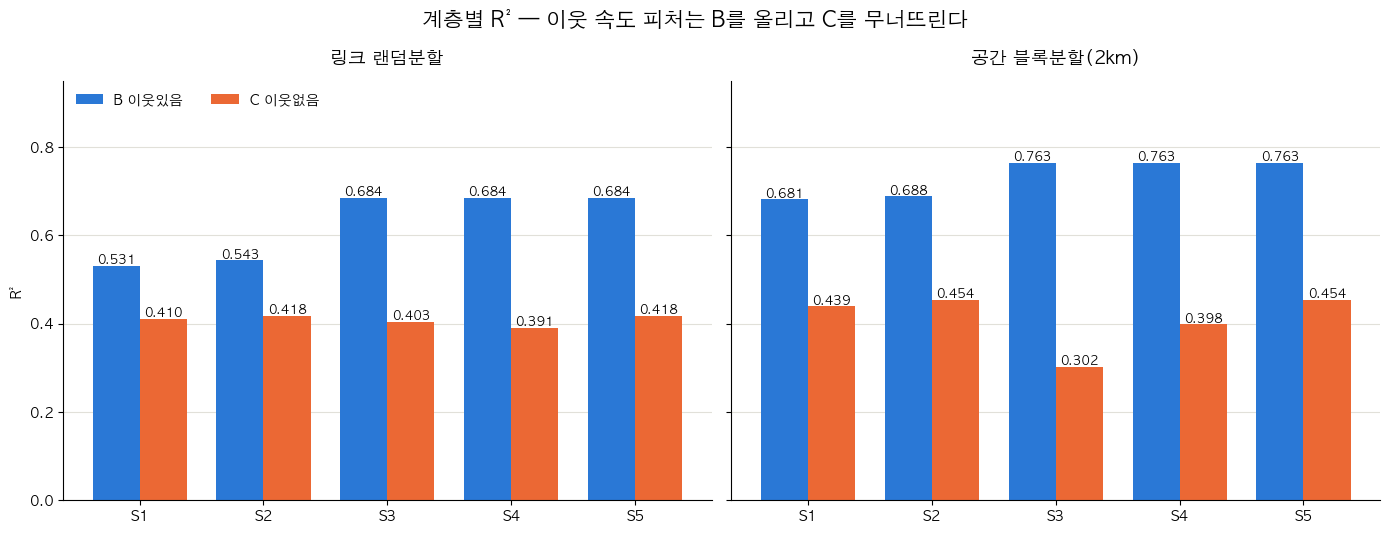

In [11]:
block_name = f"공간 블록분할({BLOCK_SIZE_M//1000}km)"
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True)

for ax, split in zip(axes, ["링크 랜덤분할", block_name]):
    sub = agg.loc[split, "r2"].unstack(0)
    sets = list(FEATURE_SETS) + ["S5 분리모델(B=S3, C=S2)"]
    x = np.arange(len(sets))
    w = 0.38
    ax.bar(x - w/2, sub.loc[sets, "B 이웃있음"], w, label="B 이웃있음", color=COLOR_B)
    ax.bar(x + w/2, sub.loc[sets, "C 이웃없음"], w, label="C 이웃없음", color=COLOR_C)
    for xi, s in zip(x, sets):
        ax.text(xi - w/2, sub.loc[s, "B 이웃있음"], f"{sub.loc[s,'B 이웃있음']:.3f}",
                ha="center", va="bottom", fontsize=9, fontweight="bold")
        ax.text(xi + w/2, sub.loc[s, "C 이웃없음"], f"{sub.loc[s,'C 이웃없음']:.3f}",
                ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_xticks(x, [s.split()[0] for s in sets])
    ax.set_title(split, fontsize=13, fontweight="bold", pad=12)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)

axes[0].set_ylabel("R²")
axes[0].legend(frameon=False, ncols=2, loc="upper left")
axes[0].set_ylim(0, 0.95)
fig.suptitle("계층별 R² — 이웃 속도 피처는 B를 올리고 C를 무너뜨린다",
             fontsize=15, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_tier_bc_r2.png", dpi=220, bbox_inches="tight")
plt.show()

## 6. 해석 — 이웃 속도 피처의 양날

### 무슨 일이 일어났나

S2 → S3(이웃 속도 추가)의 변화를 계층별로 보면 부호가 **반대**입니다.

In [12]:
delta = []
for split in results["split"].unique():
    sub = agg.loc[split, "r2"].unstack(0)
    for bucket in ["B 이웃있음", "C 이웃없음", "전체"]:
        delta.append({
            "분할": split, "계층": bucket,
            "S2 (이웃속도 없음)": sub.loc["S2 +View-T 교통량", bucket],
            "S3 (이웃속도 추가)": sub.loc["S3 +이웃속도(원본)", bucket],
            "Δ": round(sub.loc["S3 +이웃속도(원본)", bucket] - sub.loc["S2 +View-T 교통량", bucket], 3),
        })
delta_df = pd.DataFrame(delta)
print(delta_df.to_string(index=False))

          분할     계층  S2 (이웃속도 없음)  S3 (이웃속도 추가)      Δ
     링크 랜덤분할 B 이웃있음         0.543         0.684  0.141
     링크 랜덤분할 C 이웃없음         0.418         0.403 -0.015
     링크 랜덤분할     전체         0.538         0.671  0.133
공간 블록분할(2km) B 이웃있음         0.688         0.763  0.075
공간 블록분할(2km) C 이웃없음         0.454         0.302 -0.152
공간 블록분할(2km)     전체         0.508         0.402 -0.106


### 원인

훈련 데이터의 대부분은 이웃 속도가 **있는** 행입니다. LightGBM은 그 강한 피처에 크게 의존하도록 학습됩니다.
그런데 C 계층에서는 그 피처가 **결측**입니다. 모델은 결측 경로로 빠지면서, 정작 남은 정적 피처를 제대로 쓰도록 학습되지 않은 상태로 예측하게 됩니다.

즉 **훈련 시 피처 가용성과 배포 시 피처 가용성이 어긋나는 문제**입니다. 그리고 이 어긋남은 하필 **가장 정보가 부족한 링크**에서 발생합니다.

### 해결책 비교

| | 방식 | 장점 | 단점 |
| --- | --- | --- | --- |
| **S4** | 이웃 결측을 계층평균으로 채움 | 모델 1개로 끝남 | 가짜 값이라 C 회복이 부분적 |
| **S5** | B/C를 다른 모델로 예측 | C 손실 없음, 각 계층 최적 | 모델 2개 관리 |

In [13]:
fix = []
for split in results["split"].unique():
    sub_r2 = agg.loc[split, "r2"].unstack(0)
    sub_mae = agg.loc[split, "mae"].unstack(0)
    for name in ["S2 +View-T 교통량", "S3 +이웃속도(원본)", "S4 +이웃속도(결측폴백)", "S5 분리모델(B=S3, C=S2)"]:
        fix.append({"분할": split, "구성": name,
                    "B R²": sub_r2.loc[name, "B 이웃있음"], "C R²": sub_r2.loc[name, "C 이웃없음"],
                    "전체 R²": sub_r2.loc[name, "전체"], "전체 MAE": sub_mae.loc[name, "전체"]})
fix_df = pd.DataFrame(fix)
print(fix_df.to_string(index=False))

best = fix_df[fix_df["분할"] == block_name].sort_values("전체 R²", ascending=False).iloc[0]
print(f"\n→ 공간 블록분할 기준 최고 구성: {best['구성']}  (전체 R²={best['전체 R²']:.3f}, C R²={best['C R²']:.3f})")

          분할                  구성  B R²  C R²  전체 R²  전체 MAE
     링크 랜덤분할      S2 +View-T 교통량 0.543 0.418  0.538   6.131
     링크 랜덤분할        S3 +이웃속도(원본) 0.684 0.403  0.671   4.999
     링크 랜덤분할      S4 +이웃속도(결측폴백) 0.684 0.391  0.670   5.004
     링크 랜덤분할 S5 분리모델(B=S3, C=S2) 0.684 0.418  0.671   4.994
공간 블록분할(2km)      S2 +View-T 교통량 0.688 0.454  0.508   6.295
공간 블록분할(2km)        S3 +이웃속도(원본) 0.763 0.302  0.402   6.702
공간 블록분할(2km)      S4 +이웃속도(결측폴백) 0.763 0.398  0.478   6.459
공간 블록분할(2km) S5 분리모델(B=S3, C=S2) 0.763 0.454  0.522   6.181

→ 공간 블록분할 기준 최고 구성: S5 분리모델(B=S3, C=S2)  (전체 R²=0.522, C R²=0.454)


## 7. 정적 피처(View-T 교통량)는 C에서 더 중요한가?

"전체 평균에 묻혀서 작아 보였을 뿐"이라는 가설을 검증합니다. S1 → S2의 개선폭을 계층별로 비교합니다.

In [14]:
vol_gain = []
for split in results["split"].unique():
    sub = agg.loc[split, "r2"].unstack(0)
    for bucket in ["B 이웃있음", "C 이웃없음"]:
        vol_gain.append({"분할": split, "계층": bucket,
                         "S1": sub.loc["S1 정적+시간+지형+날씨", bucket],
                         "S2": sub.loc["S2 +View-T 교통량", bucket],
                         "Δ(교통량 효과)": round(sub.loc["S2 +View-T 교통량", bucket]
                                            - sub.loc["S1 정적+시간+지형+날씨", bucket], 4)})
print(pd.DataFrame(vol_gain).to_string(index=False))

print("\n=== S3 모델 피처 중요도 상위 12 (링크 랜덤분할 fold0) ===")
imp = imp_random.sort_values("gain", ascending=False)
imp["gain_share"] = (imp["gain"] / imp["gain"].sum() * 100).round(2)
print(imp.head(12)[["feature", "gain_share"]].to_string(index=False))

          분할     계층    S1    S2  Δ(교통량 효과)
     링크 랜덤분할 B 이웃있음 0.531 0.543      0.012
     링크 랜덤분할 C 이웃없음 0.410 0.418      0.008
공간 블록분할(2km) B 이웃있음 0.681 0.688      0.007
공간 블록분할(2km) C 이웃없음 0.439 0.454      0.015

=== S3 모델 피처 중요도 상위 12 (링크 랜덤분할 fold0) ===
            feature  gain_share
           nb_speed       70.99
            MAX_SPD       10.49
             LENGTH        3.40
traffic_volume_aadt        2.24
          ROAD_TYPE        2.23
        elev_mean_m        1.70
               시간코드        1.47
          ROAD_RANK        1.31
              LANES        1.20
             REST_H        1.11
       elev_delta_m        1.03
          slope_pct        0.61


## 8. 관측 링크(A 계층) — 시간 분할 기준

A 계층은 문제 성격이 다릅니다. 도로를 새로 만나는 게 아니라 **아는 도로의 미래 시각**을 맞히는 문제이므로, 링크를 숨기는 게 아니라 **날짜로 자릅니다**(과거 → 미래).

배포 시 A 계층에서 실제로 쓰는 방법인 **이력 조회표(링크 × 시간대 × 주중/주말 평균)** 를 그대로 평가합니다.

In [15]:
hist = df[["LINK_ID", "기준일", "시간코드", "is_weekend", TARGET]]
dates = np.sort(hist["기준일"].unique())
cut = dates[int(len(dates) * 0.7)]
tr_h, te_h = hist[hist["기준일"] < cut], hist[hist["기준일"] >= cut]

lut = tr_h.groupby(["LINK_ID", "시간코드", "is_weekend"], observed=True)[TARGET].mean().rename("pred").reset_index()
glb = tr_h.groupby(["시간코드", "is_weekend"], observed=True)[TARGET].mean().rename("g").reset_index()
ev = te_h.merge(lut, on=["LINK_ID", "시간코드", "is_weekend"], how="left") \
         .merge(glb, on=["시간코드", "is_weekend"], how="left")
hit_rate = ev["pred"].notna().mean()          # 폴백을 쓰지 않고 조회표로 바로 맞은 비율
ev["pred"] = ev["pred"].fillna(ev["g"]).fillna(tr_h[TARGET].mean())

a_r2 = r2_score(ev[TARGET], ev["pred"])
a_mae = mean_absolute_error(ev[TARGET], ev["pred"])
n_train_days = int(len(dates) * 0.7)
print(f"train {dates[0]}~{dates[n_train_days-1]} ({n_train_days}일) / "
      f"test {cut}~{dates[-1]} ({len(dates)-n_train_days}일)")
print(f"이력 조회표(링크×시간대×주중/주말): R²={a_r2:.4f}  MAE={a_mae:.3f} km/h  (n={len(ev):,})")
print(f"조회표 적중률(폴백 안 쓴 비율): {hit_rate:.1%}")

train 20260707~20260715 (9일) / test 20260716~20260720 (5일)
이력 조회표(링크×시간대×주중/주말): R²=0.8773  MAE=2.754 km/h  (n=5,393,618)
조회표 적중률(폴백 안 쓴 비율): 100.0%


## 9. 배포 시나리오 종합

각 계층에 실제로 적용할 방법과 그 성능을 하나의 표로 모읍니다. **분할 방식이 계층마다 다른 게 맞습니다** — 배포 시 각 계층이 실제로 마주하는 문제가 다르기 때문입니다.

- A: 날짜 분할(과거→미래) — 아는 도로의 미래 시각
- B·C: 공간 블록분할 — 본 적 없는 지역의 도로

In [16]:
blk_r2 = agg.loc[block_name, "r2"].unstack(0)
blk_mae = agg.loc[block_name, "mae"].unstack(0)

deploy = pd.DataFrame([
    {"계층": "A 관측", "링크수": len(observed), "방법": "이력 조회표(링크×시간×주중/주말)",
     "평가 분할": "날짜 순차", "R²": round(a_r2, 3), "MAE": round(a_mae, 2)},
    {"계층": "B 미관측·이웃있음", "링크수": len(tier_b), "방법": "LightGBM + 인접 실측 이웃속도 (S3)",
     "평가 분할": f"공간 블록 {BLOCK_SIZE_M//1000}km",
     "R²": round(blk_r2.loc["S3 +이웃속도(원본)", "B 이웃있음"], 3),
     "MAE": round(blk_mae.loc["S3 +이웃속도(원본)", "B 이웃있음"], 2)},
    {"계층": "C 미관측·이웃없음", "링크수": len(tier_c), "방법": "LightGBM 정적+교통량 (S2, 이웃속도 제외)",
     "평가 분할": f"공간 블록 {BLOCK_SIZE_M//1000}km",
     "R²": round(blk_r2.loc["S2 +View-T 교통량", "C 이웃없음"], 3),
     "MAE": round(blk_mae.loc["S2 +View-T 교통량", "C 이웃없음"], 2)},
])
deploy["링크 비중"] = (deploy["링크수"] / len(all_links) * 100).round(1).astype(str) + "%"
print(deploy[["계층", "링크수", "링크 비중", "방법", "평가 분할", "R²", "MAE"]].to_string(index=False))

w = deploy["링크수"] / deploy["링크수"].sum()
print(f"\n링크수 가중 평균 MAE: {(deploy['MAE'] * w).sum():.2f} km/h")
print("※ R²는 계층마다 분모(분산)가 달라 가중평균이 의미 없으므로 MAE만 합산합니다.")

        계층   링크수 링크 비중                            방법     평가 분할    R²  MAE
      A 관측 44960 70.7%           이력 조회표(링크×시간×주중/주말)     날짜 순차 0.877 2.75
B 미관측·이웃있음 14006 22.0%    LightGBM + 인접 실측 이웃속도 (S3) 공간 블록 2km 0.763 5.80
C 미관측·이웃없음  4582  7.2% LightGBM 정적+교통량 (S2, 이웃속도 제외) 공간 블록 2km 0.454 6.22

링크수 가중 평균 MAE: 3.67 km/h
※ R²는 계층마다 분모(분산)가 달라 가중평균이 의미 없으므로 MAE만 합산합니다.


In [17]:
single = blk_r2.loc["S3 +이웃속도(원본)", "C 이웃없음"]
split_model = blk_r2.loc["S2 +View-T 교통량", "C 이웃없음"]
fallback = blk_r2.loc["S4 +이웃속도(결측폴백)", "C 이웃없음"]

b2 = blk_r2.loc["S2 +View-T 교통량", "B 이웃있음"]
b3 = blk_r2.loc["S3 +이웃속도(원본)", "B 이웃있음"]

lines = [
    "=" * 70,
    "결론",
    "=" * 70,
    f"1. C 계층(미관측·이웃없음)은 서울 링크의 {len(tier_c)/len(all_links)*100:.1f}%, "
    f"연장 {summary.loc['C 미관측·이웃없음', '연장_km']:.0f}km입니다.",
    "   지금까지 이 계층만의 성능을 측정한 적이 없었습니다.",
    "",
    "2. 인접 이웃 속도 피처는 계층에 따라 효과의 부호가 반대입니다.",
    f"   - B 계층: R² {b2:.3f} -> {b3:.3f}   (개선 {b3-b2:+.3f})",
    f"   - C 계층: R² {split_model:.3f} -> {single:.3f}   (악화 {single-split_model:+.3f})",
    "   훈련 때 있던 피처가 배포 때 사라지는 계층이 있기 때문입니다.",
    "",
    "3. 해결책은 분리 모델(S5)입니다. C에서 이웃속도를 아예 빼면 손실이 사라집니다.",
    f"   결측 폴백(S4)도 {fallback:.3f}까지 회복하지만 분리 모델({split_model:.3f})에 못 미칩니다.",
    "",
    "4. View-T 교통량은 계층과 무관하게 기여가 작습니다(약 +0.01).",
    "   '전체 평균에 묻혀서 작아 보였다'는 가설은 기각됩니다. 다만 C 계층 커버리지가",
    f"   {len(vol_links & tier_c)/len(tier_c)*100:.1f}%뿐이라, 커버리지를 넓힌 뒤 재평가할 여지는 남아 있습니다.",
    f"   같은 View-T의 혼잡시간강도(Level6)를 받으면 C 커버리지가 "
    f"{len(lev6_links & tier_c)/len(tier_c)*100:.1f}%로 올라갑니다." if lev6_links else "",
]
print("\n".join(lines))

결론
1. C 계층(미관측·이웃없음)은 서울 링크의 7.2%, 연장 402km입니다.
   지금까지 이 계층만의 성능을 측정한 적이 없었습니다.

2. 인접 이웃 속도 피처는 계층에 따라 효과의 부호가 반대입니다.
   - B 계층: R² 0.688 -> 0.763   (개선 +0.075)
   - C 계층: R² 0.454 -> 0.302   (악화 -0.152)
   훈련 때 있던 피처가 배포 때 사라지는 계층이 있기 때문입니다.

3. 해결책은 분리 모델(S5)입니다. C에서 이웃속도를 아예 빼면 손실이 사라집니다.
   결측 폴백(S4)도 0.398까지 회복하지만 분리 모델(0.454)에 못 미칩니다.

4. View-T 교통량은 계층과 무관하게 기여가 작습니다(약 +0.01).
   '전체 평균에 묻혀서 작아 보였다'는 가설은 기각됩니다. 다만 C 계층 커버리지가
   1.1%뿐이라, 커버리지를 넓힌 뒤 재평가할 여지는 남아 있습니다.
   같은 View-T의 혼잡시간강도(Level6)를 받으면 C 커버리지가 29.4%로 올라갑니다.


## 팀 액션 제안

### 1. 파이프라인 — 미관측 링크 모델을 둘로 나눈다

`src/13_predict_all_link_speed.py`에서 미관측 링크를 한 모델로 처리하고 있다면, 이웃 보유 여부로 분기해야 합니다.
링크별 이웃 보유 여부는 이 노트북 1절의 `tier_b` / `tier_c` 집합으로 결정되며, 관측 링크 목록만 있으면 재계산됩니다.

### 2. 보고서 — 성능을 계층별로 보고한다

"미관측 링크 R² 0.6x" 한 줄 대신 8절의 3계층 표를 씁니다. 심사에서 "커버리지 70%인데 나머지는?"이라는 질문이 나오면 이 표가 곧 답입니다. 약점을 숨기지 않고 계층별로 다른 전략을 쓴다는 게 오히려 설계의 근거가 됩니다.

### 3. 추가 데이터 — C 계층을 덮는 것만 가치가 있다

- **받을 것: View-T 혼잡시간강도 (상세도로망 Level6, csv)** — 링크별로 "총 통행시간 중 혼잡경계속도 이하로 주행한 시간 비율(%)"입니다. 차량 GPS 프로브에서 **속도로부터 산출된 지표**라 우리 타깃과 같은 단위계이고, 무엇보다 **미관측 링크에도 값이 존재**합니다. `data/raw/traffic/seoul_lev6_2024/seoul_link_lev6_2024.shp`에 `up_its_id`/`dw_its_id`가 있어 우리 `LINK_ID`에 바로 조인됩니다.
- **같이 받을 것: 추정교통량 주말분** — 현재 보유분은 2024년 평일 기준이라, 주말 예측 시 평일 값이 그대로 들어가고 있습니다.
- **받지 않아도 되는 것: 서울 열린데이터광장 도시고속도로 5분단위 링크 속도(OA-22351)** — 도시고속국도는 이미 관측률 98%입니다.

### 4. 후속 실험

- 버스전용차로 겹침비율, 스쿨존/사고다발/과속방지턱을 이 노트북의 S2 자리에 넣고 **C 계층 기여도**를 다시 측정 (전체 평균으로는 판단 불가)
- 혼잡시간강도 결합 후 C 계층 R² 재측정 — 유의미하게 오르면 채택, 아니면 정적 피처 추가는 중단

---

### 한계

- B/C 구분은 관측 링크를 **강제로 숨겨서** 재현한 것입니다. 실제 미관측 링크는 관측 대상에서 빠진 이유(교통량이 적거나 검지기 미설치)가 있어 분포가 다를 수 있습니다.
- 공간 블록분할은 이웃 보유율이 약 9%로, 실제 미관측 링크(75.3%)보다 훨씬 낮습니다. 계층별 R²는 안정적으로 읽되, **분할별 '전체' R²는 계층 구성비가 달라 직접 비교하면 안 됩니다.**
- View-T 교통량의 시간대 매칭(시간코드 1 = 0~1시)은 12번 노트북과 동일한 순서 기반 가정입니다.
- `data/interim/nb13_feature_cache.parquet`, `nb13_results.csv`는 이 노트북 전용 산출물로 `data/README.md`의 공식 파이프라인 목록에 포함되지 않습니다.